# XGBoost — Phase 3

## Objective

Phase 2 (`02-baseline.ipynb`) left a reference: a straight line per circuit, `gap = const + a x lap_number + b x age`.
This notebook asks whether a gradient-boosted tree model (XGBoost) predicts races it has never seen better than that line,
**with curves that make sense**.

## What has to be beaten

Fitted on 2023-2024, scored on **valid 2025** (21 races), `rmse` / `rmse within driver` / `stint rmse`, in seconds:

| reference | valid 2025 |
|---|---|
| `circuit` | 0.948 / 0.695 / 15.43 |
| `circuit + driver level` | 0.832 / 0.695 / 11.71 |

The judge is **`rmse within driver`** and the stint error, not the raw RMSE: the simulator ranks strategies for one driver in
one race, where his level is a constant (`docs/01-state-and-roadmap.md`).

## Two checks that matter more than the error

1. **The predicted time must rise with tyre age.** If it does not, the model has learned something else (the speed of a
   team, the phase of the race). Section 6 reads it on the partial dependence, with and without a monotonic constraint.
2. **The error on the degradation slope** matters more than the mean error per lap. It was not defined anywhere in the
   project; section 7 defines it two ways and reports both.

## The rule on 2025

Phase 2 used 2025 to choose between specifications, and recorded that as a deviation. It is not repeated here:
**every choice (variables, depth, number of trees, constraint) is made inside 2023-2024**, by cross-validation on whole
races. 2025 is read once, with the model already chosen. 2026 is reported apart.

## 1. Setup and the table

Nothing is rebuilt here: the table comes from `f1data.build_base()`, the target from `f1data.add_target()` (once, on the
whole table), the variables and the split from `baseline`. The tree code is in `app/trees.py`.

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import baseline
import f1data
import trees

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid", context="notebook")

raw = f1data.load_raw(verbose=False)
base, _ = f1data.add_target(f1data.build_base(raw))     # the target, once, on the whole table
f1data.check_target(base)
feat = baseline.add_features(base, raw)
train, valid, apart = baseline.split(feat)
SAMPLES = [("train 2023-24", train), ("valid 2025", valid), ("apart 2026", apart)]

for name, x in SAMPLES:
    print(f"{name:14s} {len(x):>7,} laps  {x['session_key'].nunique():>3} races  "
          f"{x['circuit'].nunique():>3} circuits")

train 2023-24   38,785 laps   41 races   24 circuits
valid 2025      20,349 laps   21 races   21 circuits
apart 2026      16,857 laps   18 races   18 circuits


## 2. The reference, reproduced

The same call as section 8 of the baseline, so the two notebooks cannot quote different numbers. The cell fails if the
valid 2025 figures move away from those written in `docs/01-state-and-roadmap.md`.

**How a tree model is scored.** `baseline.predict()` has one new branch: a model that brings its own `predict` function is
called through it. `baseline.evaluate()`, `stint_table()` and `plot_residuals()` are unchanged, so XGBoost and the
reference are scored by exactly the same code, on the same laps and the same stints.

In [2]:
COLS = ["rmse", "rmse within driver", "stint rmse"]
REFS = ["circuit", "circuit + driver level"]

ref_table, ref_models = baseline.compare(train, valid, apart, specs=REFS)
print(ref_table.set_index(["model", "sample"])[COLS].round(3).to_string())

# Non-regression: the figures to beat, as written in docs/01-state-and-roadmap.md.
EXPECTED = {"circuit": (0.948, 0.695, 15.43), "circuit + driver level": (0.832, 0.695, 11.71)}
for spec, want in EXPECTED.items():
    got = baseline.evaluate(ref_models[spec], valid)
    assert np.allclose([got[c] for c in COLS], want, atol=0.006), (spec, got)
print("\nvalid 2025 matches the reference numbers of the state document.")

                                       rmse  rmse within driver  stint rmse
model                  sample                                              
circuit                train 2023-24  0.914               0.650      14.626
                       valid 2025     0.948               0.695      15.425
                       apart 2026     1.433               0.849      22.133
circuit + driver level train 2023-24  0.768               0.650       9.688
                       valid 2025     0.832               0.695      11.708
                       apart 2026     1.100               0.849      14.003

valid 2025 matches the reference numbers of the state document.


## 3. Choosing inside 2023-2024

### What is chosen

- **The variables**, as a ladder where each rung adds one thing:

| rung | variables | why |
|---|---|---|
| `base` | `lap_number`, `age`, `circuit` | the information the reference `circuit` has |
| `+ race_frac` | + lap / race distance | lap 30 is mid-race in a short race and early in a long one |
| `+ driver_level` | + mean gap of the driver over his past races | the largest structured residual of phase 2 |
| `+ compound` | + SOFT / MEDIUM / HARD | phase 1 and 2 found no gain; checked again, not expected |
| `+ track_temp` | + track temperature | listed in phase 2 as "to be decided inside 2023-2024" |

  `traffic` is never a variable: it depends on the other cars, the simulator cannot know it.
- **The depth of the trees** (2, 3, 4) and **the number of trees** (25 to 400), at a fixed learning rate of 0.05.
- **The monotonic constraint on `age`**, on or off.

`subsample` = 0.8 and `min_child_weight` = 50 are **assumed** values, not tuned.

### How

The 41 training races are cut into 5 folds **of whole races**. Each fold is predicted by a model fitted on the other
four, so every training lap gets a prediction from a model that never saw its race ("out of fold"). The criterion is
`rmse within driver` on those predictions.

The reference `circuit` is predicted out of fold on the same folds. **Its figure here is not its figure of section 2**:
with a fifth of the races removed, fewer circuits keep the two races they need for coefficients of their own, so more laps
fall on the calendar-wide fallback. The out-of-fold comparison is like for like, but it is harder on the reference than
the real setting is.

A difference between two models is given with a 95 % interval obtained by **resampling whole races** (2 000 draws), since
laps of one race are not independent.

In [3]:
folds = trees.race_folds(train)                      # 5 folds of whole races, fixed seed
print("races per fold:", [len(f) for f in folds])

DEPTHS = (2, 3, 4)
N_TREES = (25, 50, 100, 200, 400)

oof, rows = {}, []
for fs, features in trees.FEATURE_SETS.items():
    for monotone in (False, True):
        for depth in DEPTHS:
            preds = trees.cv_predict(train, features, monotone, n_trees=N_TREES, folds=folds,
                                     max_depth=depth)
            for n, p in preds.items():
                oof[fs, monotone, depth, n] = p
                e = baseline.evaluate(trees.as_model(p, "oof"), train)
                rows.append({"features": fs, "monotone": monotone, "depth": depth, "trees": n,
                             **{c: e[c] for c in COLS}})
cv = pd.DataFrame(rows)

# The reference on the same folds, so that the comparison is like for like.
ref_oof = {spec: trees.cv_reference(train, spec, folds=folds) for spec in REFS}
print("\nout of fold on 2023-2024, the reference (rmse / rmse within driver / stint rmse):")
for spec in REFS:
    e = baseline.evaluate(trees.as_model(ref_oof[spec], "oof"), train)
    print(f"  {spec:24s} " + " / ".join(f"{e[c]:.3f}" for c in COLS))

print("\nxgboost, features '+ driver_level', monotone on age - one table per metric:")
sel = cv[(cv["features"] == "+ driver_level") & cv["monotone"]]
for c in COLS:
    print(f"\n{c}")
    print(sel.pivot(index="depth", columns="trees", values=c).round(3).to_string())

races per fold: [9, 8, 8, 8, 8]

out of fold on 2023-2024, the reference (rmse / rmse within driver / stint rmse):
  circuit                  1.007 / 0.736 / 16.566
  circuit + driver level   0.874 / 0.736 / 12.157

xgboost, features '+ driver_level', monotone on age - one table per metric:

rmse
trees    25     50     100    200    400
depth                                   
2      0.920  0.850  0.817  0.832  0.908
3      0.891  0.832  0.831  0.892  0.969
4      0.866  0.829  0.861  0.930  1.014

rmse within driver
trees    25     50     100    200    400
depth                                   
2      0.790  0.733  0.694  0.673  0.676
3      0.766  0.709  0.678  0.673  0.679
4      0.736  0.690  0.677  0.680  0.688

stint rmse
trees     25      50      100     200     400
depth                                        
2      12.810  10.991  10.622  11.834  14.613
3      12.205  10.913  11.711  14.118  16.602
4      11.949  11.344  12.923  15.318  17.704


In [4]:
# Best (depth, trees) of each feature set, by out-of-fold `rmse within driver`.
best = cv.loc[cv.groupby(["features", "monotone"])["rmse within driver"].idxmin()]
best = best.set_index(["features", "monotone"]).loc[list(trees.FEATURE_SETS)]
print(best.round(3).to_string())


def key(fs, monotone=True):
    b = best.loc[(fs, monotone)]
    return fs, monotone, int(b["depth"]), int(b["trees"])


def centred(pred):
    return trees.within(trees.as_model(pred, "oof"), train)


# Is each rung better than the one before it? Difference of `rmse within driver`, races resampled.
print("\nrmse within driver, monotone models, each rung against the previous one "
      "(negative = the rung helps):")
names = list(trees.FEATURE_SETS)
prev = centred(ref_oof["circuit"])
for label, pred in [("base vs reference `circuit`", oof[key("base")])] + [
        (f"{b} vs {a}", oof[key(b)]) for a, b in zip(names, names[1:])]:
    cur = centred(pred)
    d, lo, hi = trees.boot_diff(train["session_key"], prev, cur)
    print(f"  {label:34s} {d:+.4f} s   95 % interval [{lo:+.4f}, {hi:+.4f}]")
    prev = cur

print("\nmonotone against free, same feature set, each at its own best setting:")
for fs in names:
    d, lo, hi = trees.boot_diff(train["session_key"], centred(oof[key(fs, False)]),
                                centred(oof[key(fs, True)]))
    print(f"  {fs:16s} {d:+.4f} s   [{lo:+.4f}, {hi:+.4f}]")

                         depth  trees   rmse  rmse within driver  stint rmse
features       monotone                                                     
base           False         3    100  0.988               0.685      16.662
               True          3    100  0.984               0.685      16.571
+ race_frac    False         2    200  0.988               0.675      16.957
               True          2    200  0.987               0.676      16.948
+ driver_level False         2    200  0.839               0.672      12.197
               True          2    200  0.832               0.673      11.834
+ compound     False         2    200  0.840               0.672      12.222
               True          3    200  0.894               0.673      14.178
+ track_temp   False         2    200  0.837               0.672      12.111
               True          2    200  0.829               0.673      11.722

rmse within driver, monotone models, each rung against the previous one (ne

### What the cross-validation says (2023-2024 only, 41 races)

**More trees make the raw error and the stint error worse, while `rmse within driver` barely moves.** At depth 2 the
out-of-fold `rmse` goes 0.817 s (100 trees) -> 0.832 (200) -> 0.908 (400) and the stint error 10.6 -> 11.8 -> 14.6 s, while
`rmse within driver` stays at 0.673-0.676 s from 200 trees on. Deeper is the same, sooner (depth 4, 400 trees: 1.014 s
and 17.7 s). What degrades is therefore the **mean of each (race, driver)**, not the shape inside a driver's race. This is
consistent with the trees learning levels that belong to the training races (who was fast there) and do not carry over to
another race: the failure the roadmap warned about. It is a reading of these three tables, not a demonstrated mechanism.

**The two criteria do not pick the same model.** `rmse within driver` is lowest at 200 trees of depth 2; the raw error and
the stint error are lowest at 100. The criterion was fixed before the run as `rmse within driver`, so 200 it is, and the
cost is visible in the tables: about 0.015 s of raw error and 1.2 s of stint error out of fold.

**The ladder.** Differences of out-of-fold `rmse within driver`, monotone models:

- `base` against the reference `circuit`: **-0.051 s**, interval [-0.072, -0.031]. With the same information, the trees
  predict the inside of a driver's race better than a line per circuit does, out of fold, where the reference is
  handicapped as said above.
- `+ race_frac`: -0.009 s [-0.015, -0.004]. Small, and the interval excludes zero.
- `+ driver_level`: -0.003 s [-0.013, +0.004]. **No measurable gain on `rmse within driver`**, as expected for a level
  that is constant inside a (race, driver). It is kept for the other two errors, which it moves a lot: `rmse` 0.987 ->
  0.832 s and stint error 16.9 -> 11.8 s out of fold.
- `+ compound`: -0.0001 s [-0.007, +0.007]. `+ track_temp`: +0.0003 s [-0.008, +0.008]. **No measurable gain from
  either**, so neither is kept. For the compound this is the third time the project measures it (phase 1 slope, phase 2
  offset, here).

**The monotonic constraint costs nothing measurable**: +0.001 s on every rung, and every interval contains zero. Between two models with the same error, the one that cannot predict a faster lap on an older tyre is kept.

### The model chosen

`lap_number`, `age`, `circuit`, `race_frac`, `driver_level`; depth 2; 200 trees; monotone on `age`. Depth 2 means a tree
can combine at most two variables, so the model is a sum of pairwise effects (age with circuit, age with race fraction,
and so on), nothing more intricate.

## 4. The model on races it has never seen

The chosen model is fitted once on the 41 races of 2023-2024, then scored on valid 2025 and on 2026. The unconstrained
twin (`xgb free`) is fitted beside it, only to show what the constraint changes.

Both references are in the table because they answer different questions. Against `circuit`, the fair comparison is
`rmse within driver` (neither error then contains the driver's level). Against `circuit + driver level`, which has the
same driver information as XGBoost, the fair comparison is the raw `rmse` and the stint error.

In [5]:
CHOSEN = dict(features=trees.FEATURE_SETS["+ driver_level"], max_depth=2, n_estimators=200)

models = dict(ref_models)
models["xgb free"] = trees.fit_xgb(train, monotone=False, name="xgb free", **CHOSEN)
models["xgb monotone"] = trees.fit_xgb(train, monotone=True, name="xgb monotone", **CHOSEN)
XGB = "xgb monotone"

rows = [{"model": name, "sample": s, **baseline.evaluate(m, x)}
        for name, m in models.items() for s, x in SAMPLES]
table = pd.DataFrame(rows).set_index(["model", "sample"])
print(table[COLS + ["mae", "bias", "stint bias", "stints"]].round(3).to_string())

                                       rmse  rmse within driver  stint rmse    mae   bias  stint bias  stints
model                  sample                                                                                
circuit                train 2023-24  0.914               0.650      14.626  0.693  0.000      -0.274    1798
                       valid 2025     0.948               0.695      15.425  0.724 -0.045      -1.569     847
                       apart 2026     1.433               0.849      22.133  1.123 -0.005      -0.565     549
circuit + driver level train 2023-24  0.768               0.650       9.688  0.561 -0.059      -1.126    1798
                       valid 2025     0.832               0.695      11.708  0.626 -0.078      -1.901     847
                       apart 2026     1.100               0.849      14.003  0.834 -0.164      -2.308     549
xgb free               train 2023-24  0.731               0.636       8.674  0.526 -0.000      -0.176    1798
          

In [6]:
def stint_err(model, x, within=False):
    s = baseline.stint_sums(model, x, within=within)
    return s["session_key"], s["error"]


def interval(a, b, x, metric):
    # error of model `b` minus error of model `a` on `x`, whole races resampled
    if metric == "rmse":
        return trees.boot_diff(x["session_key"], baseline.residuals(models[a], x),
                               baseline.residuals(models[b], x))
    if metric == "rmse within driver":
        return trees.boot_diff(x["session_key"], trees.within(models[a], x),
                               trees.within(models[b], x))
    within = metric == "stint rmse within driver"
    races, ea = stint_err(models[a], x, within)
    return trees.boot_diff(races, ea, stint_err(models[b], x, within)[1])


PAIRS = [("circuit", "rmse within driver"), ("circuit", "stint rmse within driver"),
         ("circuit + driver level", "rmse"), ("circuit + driver level", "stint rmse")]
for s, x in SAMPLES[1:]:
    print(f"{s}: {XGB} minus the reference (negative = xgboost has the lower error), "
          f"{x['session_key'].nunique()} races resampled")
    for ref, metric in PAIRS:
        d, lo, hi = interval(ref, XGB, x, metric)
        verdict = "lower" if hi < 0 else "higher" if lo > 0 else "no measurable difference"
        print(f"  {metric:25s} vs {ref:23s} {d:+.3f} s  [{lo:+.3f}, {hi:+.3f}]  {verdict}")
    print()

valid 2025: xgb monotone minus the reference (negative = xgboost has the lower error), 21 races resampled
  rmse within driver        vs circuit                 -0.029 s  [-0.058, -0.007]  lower
  stint rmse within driver  vs circuit                 -0.068 s  [-0.817, +0.541]  no measurable difference
  rmse                      vs circuit + driver level  -0.030 s  [-0.074, +0.005]  no measurable difference
  stint rmse                vs circuit + driver level  -0.660 s  [-1.665, +0.293]  no measurable difference

apart 2026: xgb monotone minus the reference (negative = xgboost has the lower error), 18 races resampled
  rmse within driver        vs circuit                 -0.020 s  [-0.047, +0.005]  no measurable difference
  stint rmse within driver  vs circuit                 -0.899 s  [-1.545, -0.169]  lower
  rmse                      vs circuit + driver level  +0.048 s  [-0.002, +0.094]  no measurable difference
  stint rmse                vs circuit + driver level  +1.581 s  [+0.

### What the table says

**Valid 2025 (21 races).** `xgb monotone` reaches 0.802 / **0.666** / 11.05 s against 0.832 / **0.695** / 11.71 s for
`circuit + driver level`.

- `rmse within driver`: **-0.029 s**, interval [-0.058, -0.007]. Lower, and the interval excludes zero. That is 4 % of the
  reference error.
- Stint error within (race, driver), the part that survives a comparison of two strategies of one driver: -0.07 s
  [-0.82, +0.54]. **No measurable difference.**
- Raw `rmse` against `circuit + driver level`: -0.030 s [-0.074, +0.005]. No measurable difference.
- Stint error against `circuit + driver level`: -0.66 s [-1.67, +0.29]. No measurable difference.

So on 2025 XGBoost beats the reference **on the per-lap error inside a driver's race, by a small margin, and on nothing
that concerns a stint sum**.

**2026 (18 races, new regulations, never used for anything).**

- `rmse within driver`: 0.829 against 0.849 s, -0.020 s [-0.047, +0.005]. No measurable difference.
- Stint error within (race, driver): -0.90 s [-1.55, -0.17]. Lower.
- Raw `rmse` against `circuit + driver level`: 1.148 against 1.100 s, +0.048 s [-0.002, +0.094]. No measurable difference,
  and the sign is the wrong one.
- Stint error against `circuit + driver level`: 15.58 against 14.00 s, **+1.58 s [+0.03, +3.28]. Higher**: XGBoost is
  no better than the two-stage linear reference on the absolute cost of a stint in 2026, and measurably worse.

The two samples do not tell the same story metric by metric (per lap in 2025, per stint within driver in 2026), and each
gain is small against its interval. What holds on both is weaker: **XGBoost is never measurably worse than `circuit` on
the within-driver errors, and is better on one of the two in each sample.**

**The constraint changes nothing here**: `xgb free` and `xgb monotone` are within 0.005 s per lap and 0.1 s per stint of
each other on both samples.

**The gap between training and validation is small** (`rmse within driver` 0.636 on train, 0.666 on 2025), smaller than
for the reference (0.650 / 0.695): at 200 trees of depth 2 the model is not memorising the training races.

## 5. The error on the sum of a stint

The simulator adds laps, so this is the error it inherits. Same stints as phase 2: clean laps consecutive, at least 2 of
them (847 of the 988 stints of 2025). Two readings: `absolute` is what a stint costs; `within (race, driver)` is what
is left once the mean residual of each (race, driver) is removed, i.e. what does not cancel between two strategies of
the same driver.

Phase 2 measured that residuals inside a stint are strongly correlated (lag-1 autocorrelation +0.798 raw, +0.533 with the
stint mean removed) and named it the second target of phase 3. The cell measures it again for XGBoost.

In [7]:
for within, label in [(False, "absolute"), (True, "within (race, driver)")]:
    for name in ["circuit + driver level", XGB]:
        print(f"--- {name}, valid 2025, {label} ---")
        print(baseline.stint_table(models[name], valid, within=within).round(3).to_string())
        print()

# Lag-1 autocorrelation of the residual inside a stint, as in section 9.2 of the baseline.
st = baseline.stints(valid)
usable = st[st["hole_free"] & (st["laps"] >= 3)][baseline.STINT_KEY]
print("lag-1 autocorrelation inside a stint, valid 2025 (raw / stint mean removed):")
for name in ["circuit", "circuit + driver level", XGB]:
    v = valid.assign(r=baseline.residuals(models[name], valid)).merge(usable, on=baseline.STINT_KEY)
    v = v.sort_values(baseline.STINT_KEY + ["lap_number"]).reset_index(drop=True)
    g = v.groupby(baseline.STINT_KEY)["r"]
    has_next = g.cumcount(ascending=False) > 0          # every lap but the last of its stint
    pair = lambda r: np.corrcoef(r[has_next], r.shift(-1)[has_next])[0, 1]
    print(f"  {name:24s} {pair(v['r']):+.3f} / {pair(v['r'] - g.transform('mean')):+.3f}")

--- circuit + driver level, valid 2025, absolute ---
         stints  mean laps    rmse   bias  rmse / sqrt(n)  rmse / n
bracket                                                            
1-10        154      6.416   4.380 -1.334           1.729     0.683
11-20       275     15.913   8.300 -0.810           2.081     0.522
21-30       281     24.587  12.821 -1.523           2.586     0.521
31+         137     38.226  18.720 -5.506           3.028     0.490

--- xgb monotone, valid 2025, absolute ---
         stints  mean laps    rmse   bias  rmse / sqrt(n)  rmse / n
bracket                                                            
1-10        154      6.416   4.754 -1.259           1.877     0.741
11-20       275     15.913   7.570 -0.631           1.898     0.476
21-30       281     24.587  12.923 -1.622           2.606     0.526
31+         137     38.226  16.482 -1.652           2.666     0.431

--- circuit + driver level, valid 2025, within (race, driver) ---
         stints  mea

### What the brackets say

**Absolute.** XGBoost is lower on stints of 11-20 laps (7.57 against 8.30 s) and of more than 30 laps (16.48 against
18.72 s), equal on 21-30 (12.92 against 12.82 s) and higher on the shortest (4.75 against 4.38 s). The clearest change
is the **bias on long stints**: -5.51 s for `circuit + driver level` on stints over 30 laps, **-1.65 s** for XGBoost. The
reference over-predicts the gap accumulated over a long stint; XGBoost much less so. Section 6 shows where that comes
from: its age curve flattens where the straight line keeps climbing.

**Within (race, driver).** 4.27 against 5.02 s on 11-20 laps; no better on the other three brackets (3.64 / 3.48,
6.85 / 6.65, 6.69 / 6.50 s). Overall the difference is not measurable (section 4).

**The autocorrelation is still there.** +0.714 raw and **+0.492** with the stint mean removed, against +0.533 for the
reference. Slightly lower, far from gone: the error on a 24.6-lap stint is still 12.9 s where independent per-lap errors
of 0.802 s would give 4.0 s. A model of the mean lap does not fix this, whatever its form; phase 2 said it would take a
model of the lap-to-lap error, and nothing here contradicts that.

## 6. Does the predicted time rise with tyre age?

**Partial dependence**: every lap of valid 2025 is given the same tyre age `a`, everything else on the lap is left as it
is (lap number, circuit, driver level), and the predictions are averaged. Doing it for `a` = 1 to 40 draws the effect
the model attaches to age itself. The lap number is held fixed on purpose: it carries the fuel, and age must not borrow
from it.

Limit of the tool: it creates laps that do not exist (age 40 on lap 5). The curve is only as good as the model is out
there, and 99 % of the 2025 laps have a tyre of 47 laps or less, half of them 13 or less.

Three curves: the reference `circuit` (a straight line per circuit, by construction), `xgb free` and `xgb monotone`.
Then one curve per circuit, because a pooled curve can rise while some circuits fall.

tyre age in valid 2025: 1 % 1, median 13, 99 % 47 laps

partial dependence on tyre age, valid 2025, seconds against age 1:
     circuit  xgb free  xgb monotone
age                                 
5      0.201     0.295         0.327
10     0.452     0.517         0.552
15     0.703     0.760         0.795
20     0.954     0.870         0.905
25     1.205     1.020         1.052
30     1.456     1.029         1.063
35     1.707     1.029         1.063
40     1.958     1.029         1.063

steps of one lap of age where the curve goes down (out of 39):
circuit         0
xgb free        0
xgb monotone    0

mean slope over ages 1-30 (s/lap):
circuit         0.0502
xgb free        0.0355
xgb monotone    0.0366

mean slope over ages 1-30 per circuit, valid 2025 (21 circuits):
     circuit  xgb free  xgb monotone
min  -0.0201    0.0219        0.0305
50%   0.0478    0.0352        0.0367
max   0.1179    0.0438        0.0438
circuits where it is negative:
circuit         1
xgb free        0
xgb

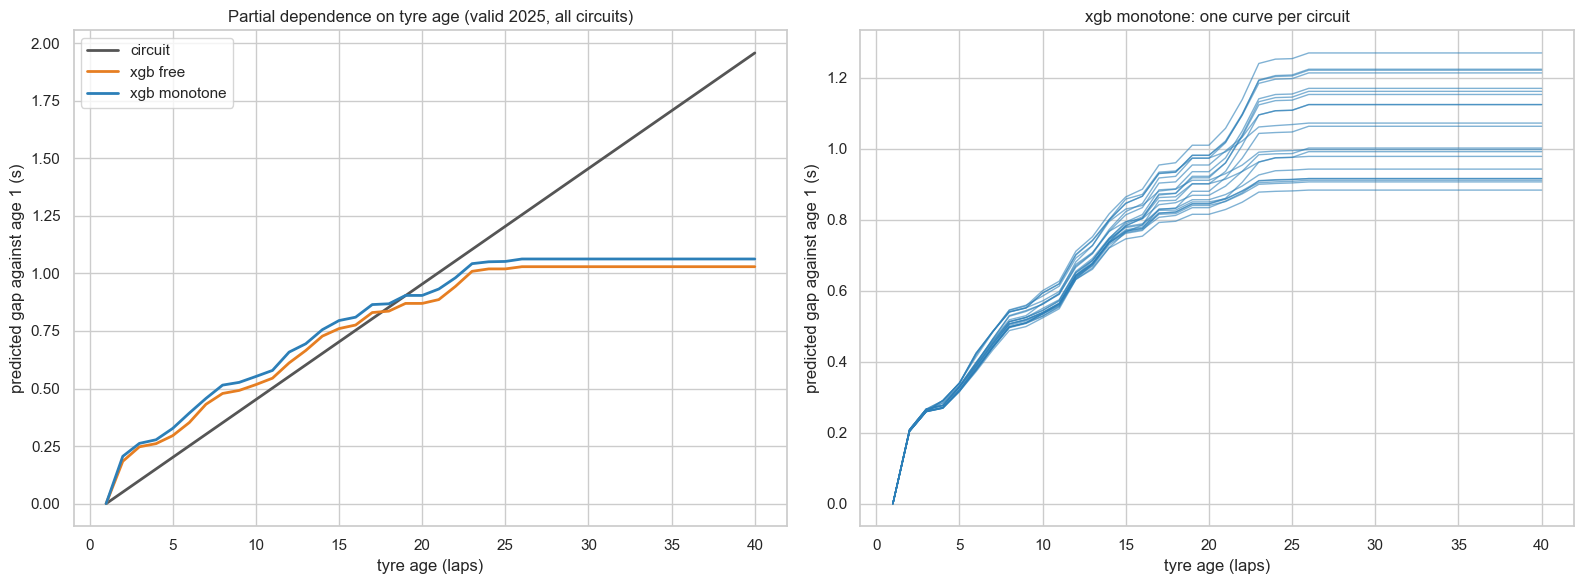

In [8]:
AGES = np.arange(1, 41)
print(f"tyre age in valid 2025: 1 % {valid['age'].quantile(0.01):.0f}, median "
      f"{valid['age'].median():.0f}, 99 % {valid['age'].quantile(0.99):.0f} laps")

CURVES = ["circuit", "xgb free", XGB]
pd_all = pd.DataFrame({name: trees.partial_dependence(models[name], valid, AGES)["all"]
                       for name in CURVES})
pd_all = pd_all - pd_all.loc[1]                       # read against a tyre of age 1
print("\npartial dependence on tyre age, valid 2025, seconds against age 1:")
print(pd_all.loc[[5, 10, 15, 20, 25, 30, 35, 40]].round(3).to_string())

steps = pd_all.diff().dropna()
print("\nsteps of one lap of age where the curve goes down (out of 39):")
print((steps < -1e-9).sum().to_string())
print("\nmean slope over ages 1-30 (s/lap):")
print(((pd_all.loc[30] - pd_all.loc[1]) / 29).round(4).to_string())

# One curve per circuit: a pooled curve can rise while some circuits fall.
per = {name: trees.partial_dependence(models[name], valid, AGES, by="circuit") for name in CURVES}
rise = pd.DataFrame({name: (p.loc[30] - p.loc[1]) / 29 for name, p in per.items()})
print(f"\nmean slope over ages 1-30 per circuit, valid 2025 ({len(rise)} circuits):")
print(rise.describe().loc[["min", "50%", "max"]].round(4).to_string())
print("circuits where it is negative:")
print((rise < 0).sum().to_string())
print("circuits with at least one downward step between ages 1 and 40:")
print(pd.Series({name: int((p.diff().dropna() < -1e-9).any().sum()) for name, p in per.items()})
      .to_string())
old = train["age"] > 30
print(f"\ntraining laps on a tyre older than 30 laps: {int(old.sum()):,} of {len(train):,} "
      f"({old.mean():.1%}), from {train.loc[old, 'session_key'].nunique()} races")
print("\ncorrelation across circuits between the xgboost slope and the reference slope: "
      f"{np.corrcoef(rise[XGB], rise['circuit'])[0, 1]:+.2f}")

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for name, colour in [("circuit", "#555555"), ("xgb free", "#e67e22"), (XGB, "#2c7fb8")]:
    ax[0].plot(AGES, pd_all[name], color=colour, lw=2, label=name)
ax[0].set(title="Partial dependence on tyre age (valid 2025, all circuits)",
          xlabel="tyre age (laps)", ylabel="predicted gap against age 1 (s)")
ax[0].legend()
curves = per[XGB] - per[XGB].loc[1]
for c in curves.columns:
    ax[1].plot(AGES, curves[c], color="#2c7fb8", lw=1, alpha=0.6)
ax[1].set(title=f"{XGB}: one curve per circuit", xlabel="tyre age (laps)",
          ylabel="predicted gap against age 1 (s)")
fig.tight_layout()

### What the curves say

**The prediction rises with tyre age.** Pooled over the 21 circuits, neither XGBoost curve has a single downward step
between ages 1 and 40, and the mean slope over ages 1-30 is positive on every circuit for both. Circuit by circuit, the
unconstrained model does have at least one downward step on **2 of the 21 circuits** (their size is not examined here);
the constrained one has none, by construction. So the unconstrained model learned wear on its own, and the constraint
removes two local dips at no measurable cost in error. (The reference, for its part, has a **negative** tyre slope on one
circuit of 2025.)

**The curve is not a straight line.** XGBoost attaches +0.33 s to the first 5 laps of age and +0.55 s to the first 10
(the line: +0.20 and +0.45 s), then bends: +0.91 s at 20, +1.05 s at 25, and **flat from age 30 on at +1.06 s**, where
the line reads +1.46 s at 30 and +1.96 s at 40. Mean slope over ages 1-30: 0.037 s/lap against 0.050.

Two readings of the plateau, **neither tested**:
- *selection*: a tyre is kept beyond 30 laps only when it is holding up, so the old-tyre laps in the data are the ones
  that did not degrade. The model then describes the stints that were driven, not what a tyre would do if it were kept
  on. For the simulator this is the dangerous reading: it would make very long stints look free.
- *not enough data*: only 3,110 of the 38,785 training laps (8.0 %) are on a tyre older than 30 laps, and with
  `min_child_weight` = 50 the trees may simply stop splitting there.

Either way **there is no cliff in this curve**, and the flat part beyond 30 laps must not be read as "an old tyre stops
losing time". `docs/04-limits-and-open-questions.md` asked whether the curve bends beyond ~25 laps: it bends, downward.

**XGBoost barely distinguishes the circuits.** Its mean slope per circuit runs from 0.031 to 0.044 s/lap; the reference's
runs from -0.020 to +0.118. The two orderings correlate at +0.56. Phase 1 published slopes from 0.024 (Melbourne) to
0.121 (Sakhir): the trees have learned mostly one calendar-wide age curve, shifted a little per circuit. Whether that is
a loss (real circuit differences ignored) or a gain (noisy per-circuit slopes shrunk) is what the next section measures.

## 7. The error on the degradation slope

Two definitions, both computed the same way for every model, both on races never seen.

**A. Per stint.** On each stint of at least 8 consecutive clean laps (8 is **assumed**), the slope of the actual gap on
lap number is compared with the slope of the predicted gap. Inside a stint, tyre age and lap number advance together, so
this slope is the **net of fuel and wear**: it is what the simulator adds along a stint, not wear alone. The `cumulative`
column converts the slope error into seconds over the stint, `error x n(n-1)/2`.

**B. Per race.** The tyre-age coefficient `b` of `gap = c + a x lap + b x age`, fitted on the held-out race (drivers
pit on different laps, which separates age from fuel), compared with the same fit on the model's **predictions** for
those laps. For the linear reference this returns its own coefficient exactly; for trees it reads the slope they imply on
the laps actually driven, with no invented tyre ages.

**B'.** The fit of B has no driver term (it is the one of `02-baseline.ipynb` section 4), so its coefficient also carries
*who* runs the old tyres. B' gives each driver a free level, as the phase 1 fit did, and reads the slope inside a
driver's race. B' was added after seeing that `circuit + driver level` scores differently from `circuit` on B, which a
pure wear measure should not allow. It changes how the slope is read, not which model was chosen.

`zero` (predict gap = 0, slope 0) is in the table as the floor: a model that does no better than `zero` on a slope has
learned nothing about it.

In [9]:
NAMES = ["zero", "circuit", "circuit + driver level", "xgb free", XGB]
models["zero"] = baseline.fit(train, "zero")


def line(name, e, ref, races):
    d, lo, hi = trees.boot_diff(races, ref["error"], e["error"])
    corr = np.corrcoef(e["predicted"], e["actual"])[0, 1] if e["predicted"].std() > 0 else np.nan
    return (f"    {name:24s} rmse {baseline.rms(e['error']):.4f}  bias {e['error'].mean():+.4f}  "
            f"corr {corr:+.2f}  vs circuit {d:+.4f} [{lo:+.4f}, {hi:+.4f}]")


print(f"A. slope per stint (s/lap), hole-free stints of >= {trees.SLOPE_MIN_LAPS} clean laps")
for s, x in SAMPLES[1:]:
    a = {name: trees.stint_slopes(models[name], x) for name in NAMES}
    act = a["circuit"]["actual"]
    print(f"\n  {s}: {len(act)} stints, actual slope mean {act.mean():+.4f}, sd {act.std():.4f}")
    for name in NAMES:
        e = a[name]
        # what the slope error costs over the stint: error x n(n-1)/2, in seconds
        cost = baseline.rms(e["error"] * e["laps"] * (e["laps"] - 1) / 2)
        print(line(name, e, a["circuit"], e["session_key"]) + f"  cumulative {cost:5.2f} s")

for per_driver, label in [(False, "B. tyre-age coefficient per race (s/lap of age), no driver "
                                  "term - the fit of 02-baseline section 4"),
                          (True, "B'. the same with a free level per driver - the slope inside "
                                 "a driver's race")]:
    print(f"\n{label}")
    for s, x in SAMPLES[1:]:
        b = {name: trees.race_age_slopes(models[name], x, per_driver) for name in NAMES}
        act = b["circuit"]["actual"]
        print(f"\n  {s}: {len(act)} races, actual coefficient mean {act.mean():+.4f}, "
              f"sd {act.std():.4f}, positive in {(act > 0).sum()}/{len(act)}")
        for name in NAMES:
            print(line(name, b[name], b["circuit"], b[name].index))

A. slope per stint (s/lap), hole-free stints of >= 8 clean laps

  valid 2025: 748 stints, actual slope mean +0.0088, sd 0.0697
    zero                     rmse 0.0702  bias -0.0088  corr +nan  vs circuit -0.0023 [-0.0082, +0.0036]  cumulative 15.18 s
    circuit                  rmse 0.0725  bias -0.0158  corr +0.19  vs circuit +0.0000 [+0.0000, +0.0000]  cumulative 15.70 s
    circuit + driver level   rmse 0.0725  bias -0.0158  corr +0.19  vs circuit +0.0000 [-0.0000, +0.0000]  cumulative 15.70 s
    xgb free                 rmse 0.0664  bias -0.0132  corr +0.36  vs circuit -0.0060 [-0.0126, +0.0004]  cumulative 13.19 s
    xgb monotone             rmse 0.0666  bias -0.0127  corr +0.35  vs circuit -0.0059 [-0.0129, +0.0014]  cumulative 13.23 s

  apart 2026: 479 stints, actual slope mean +0.0152, sd 0.1195
    zero                     rmse 0.1204  bias -0.0152  corr +nan  vs circuit +0.0024 [-0.0017, +0.0070]  cumulative 14.44 s
    circuit                  rmse 0.1180  bias -0.0175

### What the slopes say

**A. Nobody predicts the slope of a single stint.** On 2025 (748 stints) the actual slope has a standard deviation of
0.070 s/lap around a mean of +0.009. The reference's error is 0.0725 s/lap, **no better than `zero`** (0.0702; difference
-0.002 [-0.008, +0.004]). XGBoost reaches 0.0666: -0.006 s/lap against the reference, interval [-0.013, +0.001], **no
measurable difference**, though its predicted slopes follow the actual ones somewhat better (correlation +0.35 against
+0.19). On 2026 the reference and XGBoost are indistinguishable (0.118 s/lap). In seconds over the stint, the slope error is worth about
13 to 16 s on 2025 for every model. The slope of one stint is dominated by what no model here sees (traffic, tyre management, the
driver's race), so definition A cannot separate these models.

**B. On the wear slope of a race, XGBoost roughly halves the error on 2025.**

| | `circuit` | `xgb monotone` | difference, 95 % interval |
|---|---|---|---|
| B, valid 2025 (21 races) | 0.030 | 0.016 | -0.014 [-0.026, -0.002] |
| B, 2026 (18 races) | 0.044 | 0.030 | -0.015 [-0.029, -0.001] |
| B', valid 2025 | 0.028 | 0.016 | -0.012 [-0.024, +0.001] |
| B', 2026 | 0.036 | 0.027 | -0.009 [-0.023, +0.003] |

(rmse of the coefficient, s per lap of age; the actual coefficient averages +0.046 in 2025 and +0.028 in 2026 on B.)

On B both intervals exclude zero. On B', the stricter reading, the gain keeps its size on 2025 but **both intervals
reach zero**: with 21 and 18 races it is not established. The predicted slopes track the actual ones much better than
the reference's do (correlation +0.76 against +0.44 on B', 2025).

**This answers the question left open in section 6.** XGBoost uses almost one age curve for every circuit, and it is
*closer* to the slope of an unseen race than a slope fitted per circuit. So on this data, most of the between-circuit
spread of the reference's slopes (-0.020 to +0.118) does not carry over from one year to the next. It is the same finding
as phase 1's between-race dispersion, reached from the other side.

**2026.** The reference over-predicts wear by +0.017 s/lap (B') on the new cars; XGBoost's bias is +0.001. Its flatter
curve happens to suit a season with less degradation. That is not evidence that it understood 2026.

**On 2025, XGBoost under-predicts wear slightly** (bias -0.006 s/lap on B'), where the reference over-predicts it
(+0.006). Over a 25-lap stint that is about 0.006 x 300 = 1.8 s, in opposite directions.

## 8. Where XGBoost still fails

The six panels of phase 2, for the chosen model, then the residual by tyre age and compound and how the trees spend
their splits.

mean residual by tyre age and compound, valid 2025 (bins of 5 laps, >= 200 laps):
  SOFT    2:-0.159  8:-0.178  12:-0.038  18:-0.021  22:+0.065
  MEDIUM  2:+0.008  8:-0.091  12:-0.024  18:-0.025  22:-0.008  28:+0.044  32:+0.156
  HARD    2:-0.059  8:-0.139  12:-0.119  18:-0.133  22:-0.138  28:-0.103  32:-0.043  38:+0.154

share of the total gain per variable (how the trees spend their splits):
  race_frac 49.0%  driver_level 28.2%  lap_number 8.7%  age 7.4%  circuit 6.8%


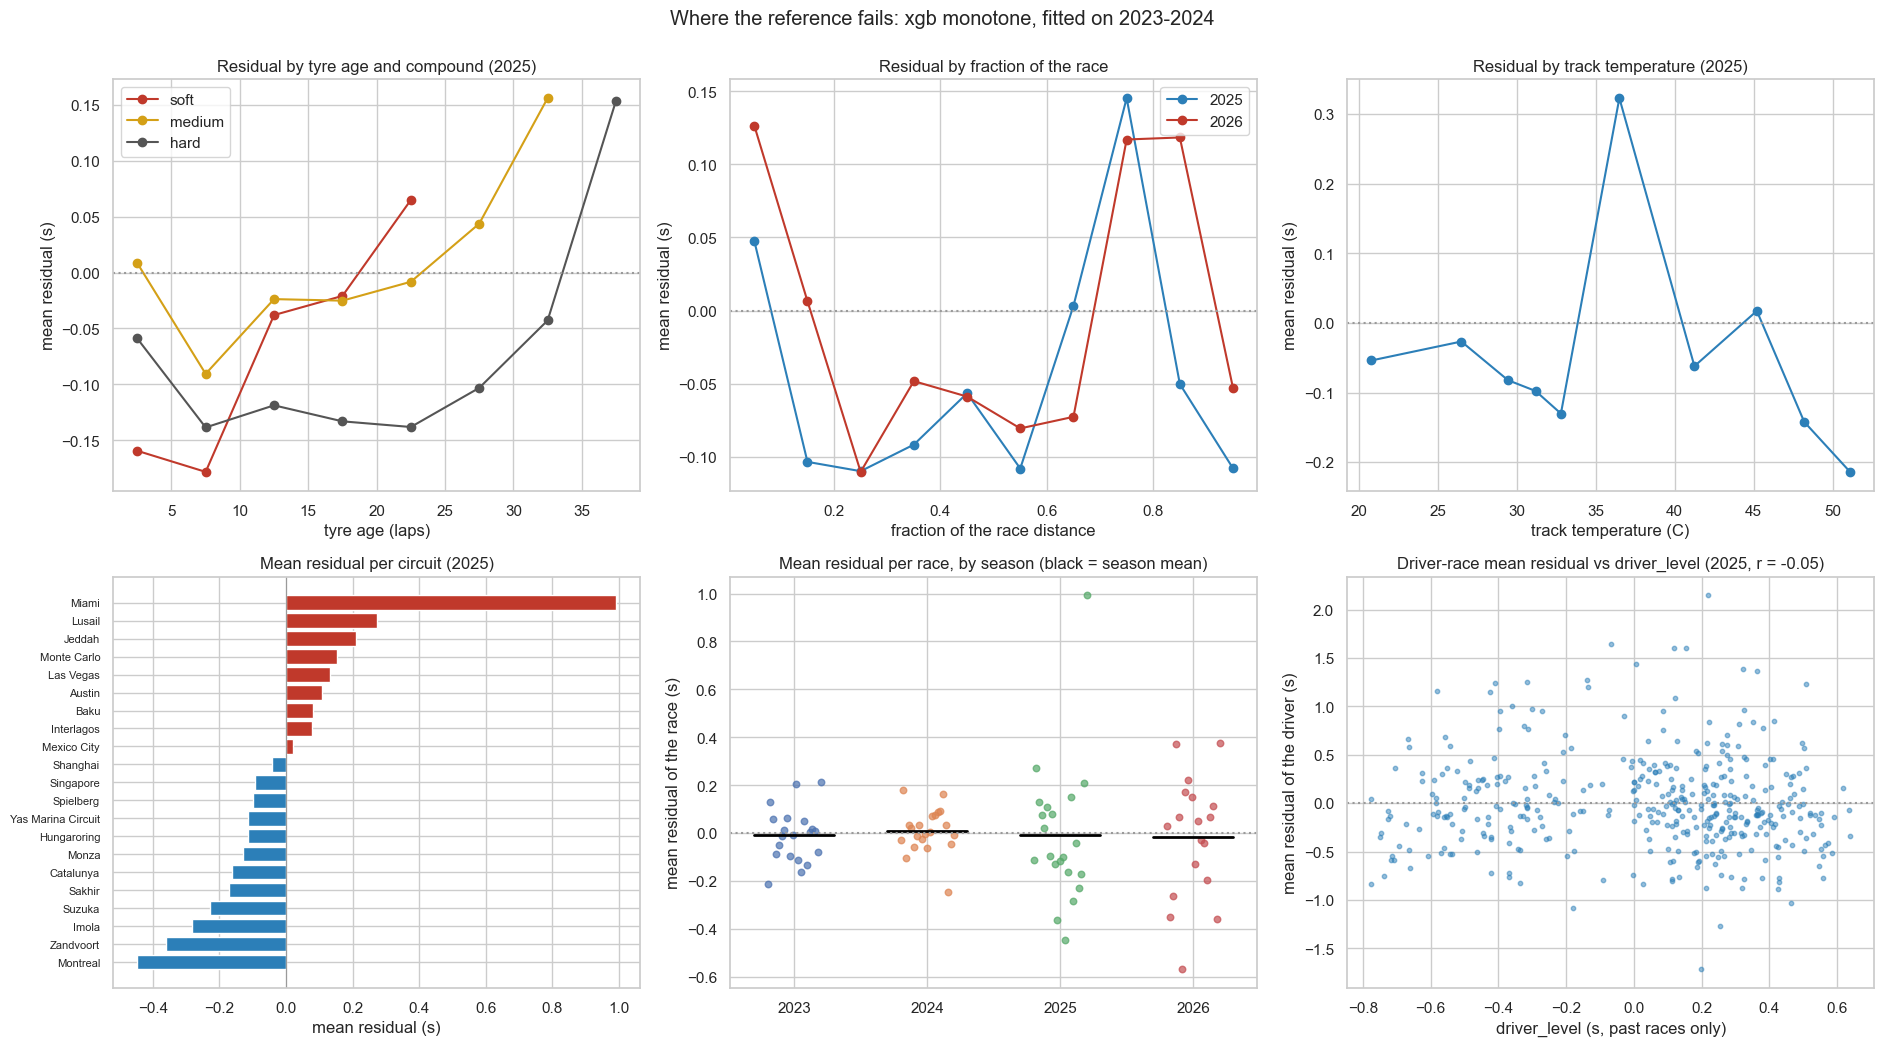

In [10]:
FIGURES = f1data.CACHE.parent / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
fig = baseline.plot_residuals(models[XGB], train, valid, apart)
fig.savefig(FIGURES / "xgboost_residuals.png", dpi=110, bbox_inches="tight")

rv = baseline.residuals(models[XGB], valid)
print("mean residual by tyre age and compound, valid 2025 (bins of 5 laps, >= 200 laps):")
for comp in f1data.COMPOUNDS:
    m = valid["compound"] == comp
    g = (rv[m].groupby(pd.cut(valid.loc[m, "age"], np.arange(0, 46, 5)), observed=True)
         .agg(["mean", "size"]))
    g = g[g["size"] >= 200]
    print(f"  {comp:7s} " + "  ".join(f"{i.mid:.0f}:{v:+.3f}" for i, v in g["mean"].items()))

gain = models[XGB]["reg"].get_booster().get_score(importance_type="total_gain")
total = sum(gain.values())
print("\nshare of the total gain per variable (how the trees spend their splits):")
print("  " + "  ".join(f"{k} {v / total:.1%}"
                       for k, v in sorted(gain.items(), key=lambda t: -t[1])))

## Findings (Phase 3)

Fitted on 2023-2024 (41 races); every choice made by cross-validation inside those races; valid 2025 (21 races) read
once; 2026 (18 races) apart.

1. **XGBoost beats the reference on unseen races, by a small margin, on one of the two metrics that judge it.**
   `rmse within driver` 0.666 s against 0.695 s on 2025: -0.029 s, interval [-0.058, -0.007]. On 2026 -0.020 s
   [-0.047, +0.005], not measurable.
2. **It does not beat it on the sum of a stint.** Stint error within (race, driver): no measurable difference on 2025,
   lower by 0.9 s on 2026. Absolute stint error against `circuit + driver level`: no measurable difference on 2025
   (11.05 against 11.71 s), **higher** on 2026 (15.58 against 14.00 s). The autocorrelation inside a stint is still
   +0.49 with the stint mean removed.
3. **The curves are coherent.** The predicted gap rises with tyre age. Without the monotonic constraint the pooled
   curve already rises and 2 of 21 circuits show a local dip; the constraint removes them, costs nothing measurable and
   is kept.
4. **The wear curve is concave and flat beyond 30 laps.** No cliff. The plateau may be a selection effect (only tyres
   that hold are kept that long) and must not be used to price very long stints. Untested.
5. **On the wear slope of an unseen race, XGBoost's error is about half the reference's** (0.016 against 0.028-0.030 s
   per lap of age on 2025). The interval excludes zero on definition B and reaches it on B'. On the slope of a single
   stint (definition A) no model, the reference included, does better than predicting zero.
6. **Compound and track temperature add nothing measurable**, inside 2023-2024.
7. **More trees or deeper trees degrade the raw error and the stint error** while `rmse within driver` stays put: the
   model then learns levels that belong to the training races.

### Residuals (section 8)

- By compound, the picture of phase 2 is unchanged: HARD is over-predicted at most ages (-0.14 to -0.10 s between ages 8
  and 28), SOFT rises from -0.18 s at age 8 to +0.07 s at 22. The compound was offered to the trees and not kept.
- The trees spend 49 % of their gain on `race_frac` and 28 % on `driver_level`; `age` gets 7 %. Most of what XGBoost adds
  is a better shape of the race-long trend (fuel, track), not a better tyre model. That is consistent with finding 2.

### Limits

- One split, 21 and 18 races. The intervals resample races but not the training set, the folds or the seed.
- `subsample`, `min_child_weight`, the learning rate and the 8-lap floor of definition A are assumed.
- The criterion (`rmse within driver`) and the raw / stint errors disagree on the number of trees (200 against 100).
- Circuits with one training race, and Madring with none, are predicted from the pooled curve.
- As in phase 2, the median of a race is not known before the race: these figures rank models, they do not forecast a
  lap time. Traffic remains out of reach (0.55 s of residual spread on a quarter of the laps).

### What this leaves for the simulator

The gain is real but small, and it is not on the quantity the simulator adds up. XGBoost's value for phase 5 is less its
error than its **shape**: a wear curve that is not a straight line changes which strategy wins, where the reference
makes the answer nearly closed-form. That shape is also where the model is least trustworthy (the plateau), so it should
be tested against the reference inside the simulator (roadmap step 6) rather than adopted on these numbers.